Теперь необходимо проанализировать теги, полученные от LLM, отфильтровать шум, оставить топ самых частых тегов и подготовить данные для обучения модели мульти-лейбл классификации.

In [246]:
import json
from collections import Counter

import matplotlib.pyplot as plt


TOP_N - количество самых популярных тегов для отбора

MIN_FREQUENCY - минимальное число фильмов с определенным тегом для включения этого тега в список

FIGSIZE - размер Figure для графиков

In [247]:
TOP_N = 50

MIN_FREQUENCY = 5

FIGSIZE = (10, 4)

In [248]:
with open("../data/processed/tags_all.json", "r", encoding="utf-8") as f:
    tags_data = json.load(f)

print(tags_data[0])

{'movie_name': '1+1', 'id': 1, 'tags': ['дружба', 'аристократия', 'сиделка', 'комедия', 'преодоление', 'взаимопомощь', 'реабилитация', 'уважение', 'французский стиль'], 'year': 2011, 'genres': 'Драма, Комедия', 'directors': 'Оливье Накаш, Эрик Толедано', 'countries': 'Франция'}


Считаем частоту тегов

In [249]:
all_tags = []
for item in tags_data:
    all_tags.extend(item['tags'])

tag_counts = Counter(all_tags)

print(f"Всего тегов (с повторами): {len(all_tags)}")
print(f"Уникальных тегов: {len(tag_counts)}")
print(f"Среднее число тегов на фильм: {len(all_tags) / len(tags_data):.2f}")

Всего тегов (с повторами): 7273
Уникальных тегов: 2332
Среднее число тегов на фильм: 9.13


Выбираем топ-N самых частых тегов

In [250]:
tags_filtered = []

for i, (tag, count) in enumerate(tag_counts.most_common(TOP_N), 1):
    if count >= MIN_FREQUENCY:
        tags_filtered.append(tag)
        print(f"{i}. {tag} - {count}")

1. опасность - 268
2. дружба - 132
3. выживание - 128
4. психология - 109
5. борьба - 106
6. любовь - 101
7. взросление - 93
8. детство - 91
9. надежда - 90
10. путешествие - 86
11. интрига - 83
12. семья - 75
13. справедливость - 73
14. расследование - 71
15. напряжение - 70
16. прошлое - 66
17. приключения - 66
18. выбор - 61
19. тайны - 59
20. убийство - 57
21. путешествие во времени - 55
22. отчаяние - 54
23. спасение - 51
24. разочарование - 51
25. братство - 50
26. будущее - 49
27. мечта - 42
28. судьба - 40
29. природа - 40
30. предательство - 39
31. романтика - 37
32. детектив - 36
33. комедия - 35
34. погоня - 35
35. киборг - 33
36. обучение - 32
37. боевик - 29
38. мистика - 29
39. страх - 28
40. изоляция - 27
41. воспоминания - 27
42. ужасы - 27
43. хаос - 25
44. постапокалипсис - 23
45. катастрофа - 22
46. изменение - 22
47. разлука - 22
48. преодоление - 21
49. утрата - 21
50. успех - 21


Нужно убрать жанры, года, слишком размытые и узконаправленные, объединить дубликаты

In [251]:
tags_genres = [
    'драма',
    'боевик',
    'комедия',
    'приключения',
    'триллер',
    'криминал',
    'детектив',
    'ужасы',
    'мелодрама',
    'фантастика',
    'фэнтези',
    'биография',
    'мультфильм',
    'спорт',
    'история',
    'вестерн',
    'мюзикл',
    'аниме',
    'документальный',
    'семейный',
    'нуар',
]
tags_years = [
    '2025 год', '2024 год', '2023 год', '2022 год', '2021 год',
    '2020-е', '2010-е', '2000-е', '90-е', '80-е', '70-е', '60-е', '50-е', '40-е',
    '2020-е годы', '2010-е годы', '2000-е годы', '90-е годы', '80-е годы', '70-е годы', '60-е годы', '50-е годы', '40-е годы',
]

tags_generic = [
    'фильм', 'кино', 'картина', 'сюжет', 'герой', 'герои',
    'персонаж', 'события', 'изменение',
]

tags_to_exclude = set(tags_genres + tags_years + tags_generic)

In [252]:
tag_mapping = {
    'путешествие во времени': 'путешествие',

    'семейные узы': 'семья',
    'семейные ценности': 'семья',
    'семейная драма': 'семья',
    'семейные тайны': 'семья',
    'семейные связи': 'семья',
    'семейная комедия': 'семья',
    
    'воспоминания': 'прошлое',
    'прошлое и настоящее': 'прошлое',
    'прошлое и будущее': 'прошлое',
    'будущее прошлое': 'прошлое',
    'тайны прошлого': 'прошлое',
    
    'тайна': 'тайны',
    'загадка': 'тайны',
    
    'друзья': 'дружба',
    'взаимоотношения': 'отношения',
    'взаимопонимание': 'отношения',
    
    'киборги': 'киборг',
    
    'борьба за выживание': 'выживание',
    'борьба за жизнь': 'выживание',

    'геройство': 'героизм',
    
    'криминальная комедия': 'комедия',
    'лондонский криминал': 'криминал',
    'детективная история': 'детектив',
    
    'советский юмор': 'советский',
    
    'драматичный': 'драма',
    'драматичный сюжет': 'драма',
    
    'волшебство': 'магия',
    'фантазия': 'магия',
}

In [253]:
tag_remap_counts = Counter()

for item in tags_data:
    clean_tags = []
    for tag in item['tags']:
        tag_lower = tag.lower().strip()
        
        if tag_lower in tags_to_exclude:
            continue
        
        mapped = tag_mapping.get(tag_lower, tag_lower)
        
        if mapped in tags_to_exclude:
            continue
        
        tag_remap_counts[mapped] += 1
        clean_tags.append(mapped)

    item['clean_tags'] = clean_tags

In [254]:
tags_final = []

for i, (tag, count) in enumerate(tag_remap_counts.most_common()):
    if count >= MIN_FREQUENCY and not(tag in tags_to_exclude):
        tags_final.append(tag)
        print(f"{i}. {tag} - {count}")
    else:
        print(f"ИСКЛЮЧЕН: {i}. {tag} - {count}")
    if len(tags_final) >= TOP_N:
        break

final_tags_set = set(tags_final)

0. опасность - 268
1. путешествие - 141
2. дружба - 139
3. выживание - 138
4. семья - 121
5. прошлое - 112
6. психология - 109
7. борьба - 106
8. любовь - 101
9. взросление - 93
10. детство - 91
11. надежда - 90
12. тайны - 87
13. интрига - 83
14. справедливость - 73
15. расследование - 71
16. напряжение - 70
17. выбор - 61
18. убийство - 57
19. отчаяние - 54
20. киборг - 52
21. спасение - 51
22. разочарование - 51
23. братство - 50
24. будущее - 49
25. мечта - 42
26. судьба - 40
27. природа - 40
28. предательство - 39
29. романтика - 37
30. магия - 36
31. погоня - 35
32. обучение - 32
33. мистика - 29
34. страх - 28
35. изоляция - 27
36. хаос - 25
37. постапокалипсис - 23
38. отношения - 23
39. катастрофа - 22
40. разлука - 22
41. преодоление - 21
42. утрата - 21
43. успех - 21
44. полиция - 20
45. философия - 19
46. школа - 18
47. героизм - 18
48. дом - 18
49. открытие - 18


In [255]:
tags_distribution = Counter()
movies_with_tags = []
movies_without_tags = []

for item in tags_data:
    filtered = [t for t in item['clean_tags'] if t in final_tags_set]
    
    if filtered:
        movies_with_tags.append(item)
        tags_distribution[len(filtered)] += 1
    else:
        movies_without_tags.append(item)

print(f"Всего фильмов: {len(tags_data)}")
print(f"Фильмов с тегами: {len(movies_with_tags)}")
print(f"Фильмов без тегов: {len(movies_without_tags)}")
print(f"Потери: {len(movies_without_tags) / len(tags_data) * 100:.1f}%")

print("Примеры фильмов без тегов:")
for item in movies_without_tags[:10]:
    print(f"{item['movie_name']}: {item['tags']}")

Всего фильмов: 797
Фильмов с тегами: 744
Фильмов без тегов: 53
Потери: 6.6%
Примеры фильмов без тегов:
Джентльмены: ['криминальная комедия', 'аристократия', 'британская преступность', 'лондонский криминал', 'еврейская диаспора', 'китайцы', 'спортсмены', 'олигархи', 'нелегальный бизнес']
Большой куш: ['криминальная интрига', 'борьба за алмаз', 'подпольный бокс', 'лондонский дон', 'опасность на стадионе', 'гангстерская мелочь', 'кража и преследование', 'азарт и риск', 'неожиданные союзы', 'хаос в Лондоне']
Пираты Карибского моря: Проклятие Черной жемчужины: ['приключения', 'похищение', 'борьба за власть', 'морские приключения', 'опасность на море', 'кража', 'романтическое противостояние', 'поиски сокровищ', 'судьба корабля', 'океанская тайна']
Приключения Паддингтона 2: ['приключения', 'медведь', 'антикварный магазин', 'похищение']
Диодорова. Против течения: ['спортивный подвиг', 'борьба за мечту', 'преодоление себя', 'женская сила', 'настойчивость', 'путь к вершине', 'достижения', 'труд

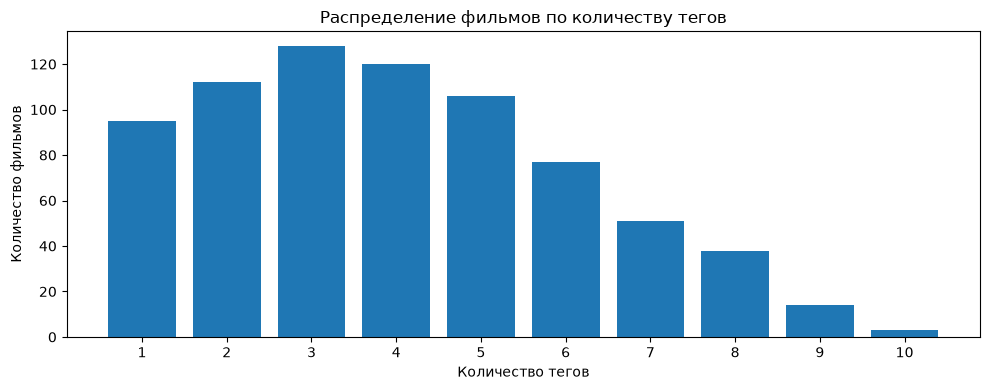

In [256]:
counts_keys = sorted(tags_distribution.keys())
counts_values = [tags_distribution[k] for k in counts_keys]

plt.figure(figsize=FIGSIZE)
plt.bar(counts_keys, counts_values)
plt.xlabel('Количество тегов')
plt.ylabel('Количество фильмов')
plt.title('Распределение фильмов по количеству тегов')
plt.xticks(counts_keys)
plt.tight_layout()
plt.show()